# Splitting and evaluation design

Exploration behind the validation choices in `config.yaml` and `src/splitting.py`:

1. **Grouped CV on `customer_id`**: customers appear in several rows, but no single customer is bigger than a fold, so no rows need to be dropped.
2. **`StratifiedGroupKFold`, 5 folds, `shuffle=True`**: its folds have even sizes and positive rates, and it gives the most stable estimate across seeds (compared with `GroupKFold` and 3/10 folds).
3. **No holdout**: nested CV with this splitter in both loops gives the honest estimate, so every labelled row is used (all checks below use every row).
4. **Time split as a second opinion**: `TimeSeriesSplit` in date order with a **98-day gap**, the gap between `train.csv` and `test.csv`.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupKFold, StratifiedGroupKFold, cross_val_score

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

from main import deep_merge, load_config
from src.cleaning import clean
from src.data import load_raw
from src.models import build_pipeline
from src.splitting import build_cv, time_series_folds
from src.train import load_training_data

cfg = deep_merge(load_config(), {"cv": {"strategy": "stratified_group"}})
X, y, groups, dates = load_training_data(cfg, "classification")  # same rows as `python main.py train`
test = clean(load_raw(cfg, "test_file"), cfg)
group_col, date_col = cfg["data"]["group_column"], cfg["data"]["date_column"]

## 1. Rows per customer

The biggest customers in train, compared with the expected fold size. If a customer had more rows than a fold, no grouped split could keep the folds balanced, and we would have to drop its oldest purchases. The test column shows whether these customers come back in the test set.

In [2]:
rows_per_customer = groups.value_counts()
fold_size = len(X) / cfg["cv"]["n_splits"]
print(f"{len(X)} rows, {rows_per_customer.size} customers, expected fold size ~{fold_size:.0f} rows")
print(rows_per_customer.describe().round(1).to_string())

top = rows_per_customer.head(5).rename("train_rows").to_frame()
top["share_of_train"] = (top["train_rows"] / len(X)).round(3)
top["share_of_one_fold"] = (top["train_rows"] / fold_size).round(3)
top["test_rows"] = test[group_col].value_counts().reindex(top.index, fill_value=0)
top

6534 rows, 610 customers, expected fold size ~1307 rows
count    610.0
mean      10.7
std       20.0
min        1.0
25%        1.0
50%        4.0
75%       12.0
max      277.0


,train_rows,share_of_train,share_of_one_fold,test_rows
customer_id,,,,
103940,277,0.042,0.212,0
258332,203,0.031,0.155,43
755628,112,0.017,0.086,15
519184,89,0.014,0.068,33
151492,89,0.014,0.068,9


**Decision:** the biggest customer fills about a fifth of one fold, well under a whole fold, so capping rows per customer is not needed. Several big customers also return in the test set, which is one more reason to keep their history.

## 2. Fold composition of `StratifiedGroupKFold`

The project's splitter (`build_cv`) with the config settings, only changing the seed. `biggest_customer_share` is the fraction of the validation fold that belongs to its largest customer.

In [3]:
def fold_summary(cfg, seed):
    """One row per validation fold: size, positive rate and the share of its biggest customer."""
    cv = build_cv({**cfg, "seed": seed})
    rows = []
    for fold, (_, val_idx) in enumerate(cv.split(X, y, groups)):
        val_groups = groups.iloc[val_idx].value_counts()
        rows.append({"seed": seed, "fold": fold, "size": len(val_idx), "customers": val_groups.size,
                     "positive_rate": round(y.iloc[val_idx].mean(), 3), "biggest_customer": val_groups.index[0],
                     "biggest_customer_share": round(val_groups.iloc[0] / len(val_idx), 3)})
    return rows

folds = pd.DataFrame([row for seed in [cfg["seed"], 0, 1, 2] for row in fold_summary(cfg, seed)])
print(f"overall positive rate: {y.mean():.3f}")
display(folds[folds["seed"] == cfg["seed"]])
# Range of each check across the folds, per seed
folds.groupby("seed")[["size", "positive_rate", "biggest_customer_share"]].agg(["min", "max"])

overall positive rate: 0.559


,seed,fold,size,customers,positive_rate,biggest_customer,biggest_customer_share
0,42,0,1305,134,0.559,258332,0.156
1,42,1,1308,121,0.559,755628,0.086
2,42,2,1308,114,0.560,151492,0.068
3,42,3,1307,116,0.560,519184,0.068
4,42,4,1306,125,0.558,103940,0.212


size       positive_rate        biggest_customer_share       
       min   max           min    max                    min    max
seed                                                               
0     1304  1312         0.558  0.561                  0.068  0.212
1     1305  1313         0.558  0.560                  0.068  0.212
2     1304  1315         0.558  0.560                  0.068  0.211
42    1305  1308         0.558  0.560                  0.068  0.212

**Reading:** fold sizes and positive rates are nearly identical for every seed. The big customers land in the same fold whatever the seed: the shuffle only reorders customers that tie in the splitter's balancing order (mostly small ones), so seeds move small customers around but not the large ones. This is also why `shuffle=False` would add nothing: it is the same split with one fixed order, and without seeds there is no way to check its stability.

## 3. Stability of the grouped designs

A good design gives nearly the same estimate whatever its random seed. Each design runs `n_seeds` times with a different seed; the model's own seed stays fixed, so any spread comes from the design alone.

- **StratifiedGroupKFold, 3 / 5 / 10 folds**: also keeps the positive rate similar across folds.
- **GroupKFold, 3 / 5 / 10 folds**: balances the number of customers per fold, without looking at the target.

> "GroupKFold … attempts to create balanced folds such that the number of distinct groups is approximately the same in each fold, whereas StratifiedGroupKFold attempts to create folds which preserve the percentage of samples from each class as much as possible given the constraint of non-overlapping groups between splits." ([scikit-learn docs](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html))

Time-based designs are left out: they use no seed, so this test says nothing about them.

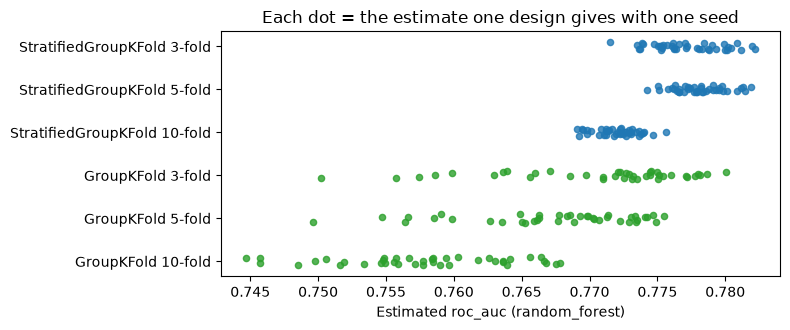

,mean estimate,spread of the estimate (std over 40 seeds),std of fold scores (seed 0),seconds per run
design,,,,
StratifiedGroupKFold 3-fold,0.7772,0.0026,0.0220,0.6000
StratifiedGroupKFold 5-fold,0.7781,0.0019,0.0287,1.0624
StratifiedGroupKFold 10-fold,0.7720,0.0016,0.0543,2.1530
GroupKFold 3-fold,0.7707,0.0070,0.0155,0.5923
GroupKFold 5-fold,0.7674,0.0062,0.0380,1.0141
GroupKFold 10-fold,0.7579,0.0063,0.0430,2.0572


In [4]:
metric = cfg["cv"]["metrics"][0]
n_seeds = 40
designs = {f"{cls.__name__} {k}-fold": (lambda s, cls=cls, k=k: cls(k, shuffle=True, random_state=s))
           for cls in (StratifiedGroupKFold, GroupKFold) for k in (3, 5, 10)}
pipe = build_pipeline("classification", cfg)
rows, estimates = [], {}
for name, make_splitter in designs.items():
    start = time.perf_counter()
    fold_scores = [cross_val_score(pipe, X, y, groups=groups, cv=make_splitter(s), scoring=metric)
                   for s in range(n_seeds)]
    est = [scores.mean() for scores in fold_scores]
    estimates[name] = est
    rows.append({"design": name, "mean estimate": np.mean(est),
                 f"spread of the estimate (std over {n_seeds} seeds)": np.std(est, ddof=1),
                 "std of fold scores (seed 0)": np.std(fold_scores[0], ddof=1),
                 "seconds per run": (time.perf_counter() - start) / n_seeds})

rng = np.random.default_rng(cfg["seed"])
fig, ax = plt.subplots(figsize=(8, 3.4))
for i, (name, est) in enumerate(estimates.items()):
    ax.scatter(est, i + rng.uniform(-0.1, 0.1, n_seeds), alpha=0.8, s=20,
               color="#1f77b4" if name.startswith("Stratified") else "#2ca02c")
ax.set_yticks(range(len(estimates)), list(estimates)); ax.invert_yaxis()
ax.set_xlabel(f"Estimated {metric} ({cfg['models']['classification']['type']})")
ax.set_title("Each dot = the estimate one design gives with one seed")
plt.tight_layout(); plt.show()
pd.DataFrame(rows).set_index("design").round(4)

**Decision:** `StratifiedGroupKFold` with 5 folds. Every stratified design moves 2–4× less across seeds than its `GroupKFold` counterpart (std about 0.002 vs 0.006–0.007), because stratifying keeps the positive rate the same in every fold. 10 folds is only marginally steadier than 5, costs twice the fits (which multiplies inside nested CV), and its smaller validation folds disagree more (larger fold std), since one big customer then weighs more. 5 folds is the balance; 3 folds trains each model on only two thirds of the rows.

## 4. Time split with the train-test gap

`test.csv` holds later purchases than `train.csv`. The time split should leave the same gap between each fold's training and validation rows.

In [5]:
train_test_gap = test[date_col].min() - dates.max()
print(f"train: {dates.min():%Y-%m-%d} to {dates.max():%Y-%m-%d}")
print(f"test:  {test[date_col].min():%Y-%m-%d} to {test[date_col].max():%Y-%m-%d}")
print(f"gap between train and test: {train_test_gap.days} days (config: cv.time_gap_days = {cfg['cv']['time_gap_days']})")

train: 2015-07-11 to 2025-02-15
test:  2025-05-24 to 2026-10-06
gap between train and test: 98 days (config: cv.time_gap_days = 98)


In [6]:
# The project's time split (src/splitting.py), as used by cv.strategy: time_series
for i, (tr, va) in enumerate(time_series_folds(dates, cfg["cv"]["n_splits"], cfg["cv"]["time_gap_days"]), start=1):
    print(f"fold {i}: train {len(tr)} rows up to {dates.iloc[tr].max():%Y-%m-%d}, "
          f"validate {len(va)} rows ({dates.iloc[va].min():%Y-%m-%d} to {dates.iloc[va].max():%Y-%m-%d}), "
          f"gap {(dates.iloc[va].min() - dates.iloc[tr].max()).days} days")

Time split: 65 rows without a purchase date are left out of the folds.
fold 1: train 934 rows up to 2017-05-06, validate 1078 rows (2017-08-12 to 2019-01-12), gap 98 days
fold 2: train 1914 rows up to 2018-10-06, validate 1078 rows (2019-01-12 to 2020-10-03), gap 98 days
fold 3: train 3077 rows up to 2020-06-27, validate 1078 rows (2020-10-03 to 2022-03-05), gap 98 days
fold 4: train 4180 rows up to 2021-11-27, validate 1078 rows (2022-03-05 to 2023-09-25), gap 98 days
fold 5: train 5185 rows up to 2023-06-19, validate 1078 rows (2023-09-25 to 2025-02-15), gap 98 days


**Decision:** `cv.time_gap_days: 98`. Every fold leaves at least that gap, and the first folds train on few rows, so the time split is used only as a second opinion on the best tuned models, not for tuning. Rows without a purchase date cannot be placed in time and are left out of these folds (whether to impute them is a cleaning decision).